# Predictive Maintenance for Engine Failure Detection Using Machine Learning


## Synopsis

### Background

Engine failures and unexpected equipment breakdowns represent a significant challenge across the automotive and machinery sectors, often resulting in high repair costs, operational downtime, reduced productivity, and potential safety risks. Conventional maintenance strategies are generally based on predefined service intervals or reactive intervention after a fault has occurred. Such approaches may not adequately reflect the actual operating condition of an engine and can result in either premature maintenance or unexpected failures.

Predictive maintenance provides a data-driven alternative by utilising historical and real-time sensor information to assess engine health and identify indications of potential failure. Machine learning techniques can analyse complex relationships among multiple operational parameters and support the early identification of conditions associated with maintenance requirements.

### Problem Statement

Engines continuously generate operational data through sensors that monitor parameters such as **revolutions per minute (RPM), temperature, pressure, and other measurements related to engine performance**. Variations in these parameters may provide valuable information regarding the operational condition and health of an engine.

However, manually assessing multiple sensor readings and identifying meaningful patterns can be challenging, particularly when dealing with large volumes of data and engines operating under different conditions. Therefore, there is a need for an automated predictive approach capable of analysing sensor measurements and determining whether an engine is operating normally or requires maintenance.


### Aim and Objective

The primary aim of this project is to develop a **machine learning-based predictive maintenance model** for engine condition classification.

The principal objective is to analyse engine sensor data and develop a classification model capable of distinguishing between:

- **Normal operating conditions**, where maintenance is not currently required.
- **Maintenance-required conditions**, where sensor characteristics indicate a potential need for intervention.

The project will investigate the relationships between engine sensor variables and the target maintenance condition to determine whether these measurements can be effectively utilised for predictive maintenance.



### Dataset Context

The dataset consists of engine health and operational parameters representing both large and small engine applications. These may include engines associated with vehicles, lawnmowers, portable generators, and other forms of compact machinery.

Different categories of engines naturally operate across different ranges of RPM, temperature, pressure, and related parameters. Consequently, the dataset represents a range of operating conditions rather than a single engine configuration. This provides an appropriate context for investigating whether machine learning techniques can identify patterns associated with maintenance requirements across varying engine characteristics.

In [1]:
import os
import shutil
import pandas as pd
from google.colab import files

# 1. Create master folder and subfolder "data"
master_folder = "predictive_maintenance_project"
data_subfolder = os.path.join(master_folder, "data")
os.makedirs(data_subfolder, exist_ok=True)
print(f"Directory structure created: ./{data_subfolder}/")

# 2. Interactive File Upload Utility
source_file = "engine_data.csv"
dest_file = os.path.join(data_subfolder, "engine_data.csv")

if not os.path.exists(source_file) and not os.path.exists(dest_file):
    print("\n[ACTION REQUIRED] 'engine_data.csv' not found. Please upload it below:")
    uploaded = files.upload()
    for fn in uploaded.keys():
        if fn != source_file:
            os.rename(fn, source_file)
            print(f"Renamed uploaded file {fn} to {source_file}")

# Move dataset to the data subfolder
if os.path.exists(source_file):
    shutil.copy(source_file, dest_file)
    print(f"Dataset successfully registered at: {dest_file}")
elif os.path.exists(dest_file):
    print(f"Dataset already registered at: {dest_file}")
else:
    print(f"ERROR: Could not find or register '{source_file}'. Please run this cell again and upload the file.")

# 3. Validation script and summary generator
expected_columns = [
    'Engine rpm', 'Lub oil pressure', 'Fuel pressure',
    'Coolant pressure', 'lub oil temp', 'Coolant temp', 'Engine Condition'
]

def validate_and_summarize(file_path):
    print(f"\n--- Validating Dataset: {file_path} ---")
    if not os.path.exists(file_path):
        print("ERROR: Dataset file not found!")
        return None

    df = pd.read_csv(file_path)

    # Check columns
    missing_cols = [col for col in expected_columns if col not in df.columns]
    if missing_cols:
        print(f"WARNING: Missing expected columns: {missing_cols}")
    else:
        print("SUCCESS: All expected columns are present and accounted for!")

    print("\n--- Dataset Overview ---")
    print(f"Total Rows (Records): {df.shape[0]:,}")
    print(f"Total Columns (Features): {df.shape[1]}")

    print("\n--- Missing Values Check ---")
    missing_counts = df.isnull().sum()
    if missing_counts.sum() == 0:
        print("No missing values detected in the dataset.")
    else:
        print(missing_counts)

    print("\n--- Target Class Distribution (Engine Condition) ---")
    if 'Engine Condition' in df.columns:
        counts = df['Engine Condition'].value_counts()
        percentages = df['Engine Condition'].value_counts(normalize=True) * 100
        for val in counts.index:
            print(f"State {val}: {counts[val]:,} samples ({percentages[val]:.2f}%)")

    print("\n--- Summary Statistics ---")
    display(df.describe())

    return df

# Run validation if file is present
if os.path.exists(dest_file):
    df_engine = validate_and_summarize(dest_file)


Directory structure created: ./predictive_maintenance_project/data/

[ACTION REQUIRED] 'engine_data.csv' not found. Please upload it below:


Saving engine_data.csv to engine_data.csv
Dataset successfully registered at: predictive_maintenance_project/data/engine_data.csv

--- Validating Dataset: predictive_maintenance_project/data/engine_data.csv ---
SUCCESS: All expected columns are present and accounted for!

--- Dataset Overview ---
Total Rows (Records): 19,535
Total Columns (Features): 7

--- Missing Values Check ---
No missing values detected in the dataset.

--- Target Class Distribution (Engine Condition) ---
State 1: 12,317 samples (63.05%)
State 0: 7,218 samples (36.95%)

--- Summary Statistics ---


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
count,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000
mean,791.239263,3.303775,6.655615,2.335369,77.643420,78.427433,0.630509
std,267.611193,1.021643,2.761021,1.036382,3.110984,6.206749,0.482679
min,61.000000,0.003384,0.003187,0.002483,71.321974,61.673325,0.000000
25%,593.000000,2.518815,4.916886,1.600466,75.725990,73.895421,0.000000
50%,746.000000,3.162035,6.201720,2.166883,76.817350,78.346662,1.000000
75%,934.000000,4.055272,7.744973,2.848840,78.071691,82.915411,1.000000
max,2239.000000,7.265566,21.138326,7.478505,89.580796,195.527912,1.000000


## Exploratory Data Analysis


### Data Overview
Load dataset directly from repository folder and study the data

In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv('predictive_maintenance_project/data/engine_data.csv')

# Overview
print(f"Dataset Shape: {df.shape}")
print(f"Feature Columns: {df.columns.tolist()}")
print("\nFirst 5 Rows:")
display(df.head())

print("\nSummary Statistics:")
display(df.describe())

Dataset Shape: (19535, 7)
Feature Columns: ['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp', 'Engine Condition']

First 5 Rows:


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0



Summary Statistics:


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
count,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000
mean,791.239263,3.303775,6.655615,2.335369,77.643420,78.427433,0.630509
std,267.611193,1.021643,2.761021,1.036382,3.110984,6.206749,0.482679
min,61.000000,0.003384,0.003187,0.002483,71.321974,61.673325,0.000000
25%,593.000000,2.518815,4.916886,1.600466,75.725990,73.895421,0.000000
50%,746.000000,3.162035,6.201720,2.166883,76.817350,78.346662,1.000000
75%,934.000000,4.055272,7.744973,2.848840,78.071691,82.915411,1.000000
max,2239.000000,7.265566,21.138326,7.478505,89.580796,195.527912,1.000000


### Data preparation
Perform data cleaning and remove unnecessary columns

In [3]:
# Data Cleaning Checks
missing_counts = df.isnull().sum()
print("\n--- Missing Values Check ---")
if missing_counts.sum() == 0:
    print("Zero missing values found across all columns.")
else:
    print(missing_counts)

# Drop any accidental unnamed/index columns if present
unnamed_cols = [col for col in df.columns if 'unnamed' in col.lower()]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)
    print(f"\nDropped unnecessary index columns: {unnamed_cols}")
else:
    print("\nNo unnecessary index columns detected.")

# Check for duplicate rows
initial_row_count = len(df)
df = df.drop_duplicates()
duplicates_removed = initial_row_count - len(df)
print(f"Duplicate rows removed: {duplicates_removed}")

# Final cleaned shape
print(f"\nFinal Cleaned Dataset Shape: {df.shape}")
display(df.head())


--- Missing Values Check ---
Zero missing values found across all columns.

No unnecessary index columns detected.
Duplicate rows removed: 0

Final Cleaned Dataset Shape: (19535, 7)


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0


### Univariate analysis

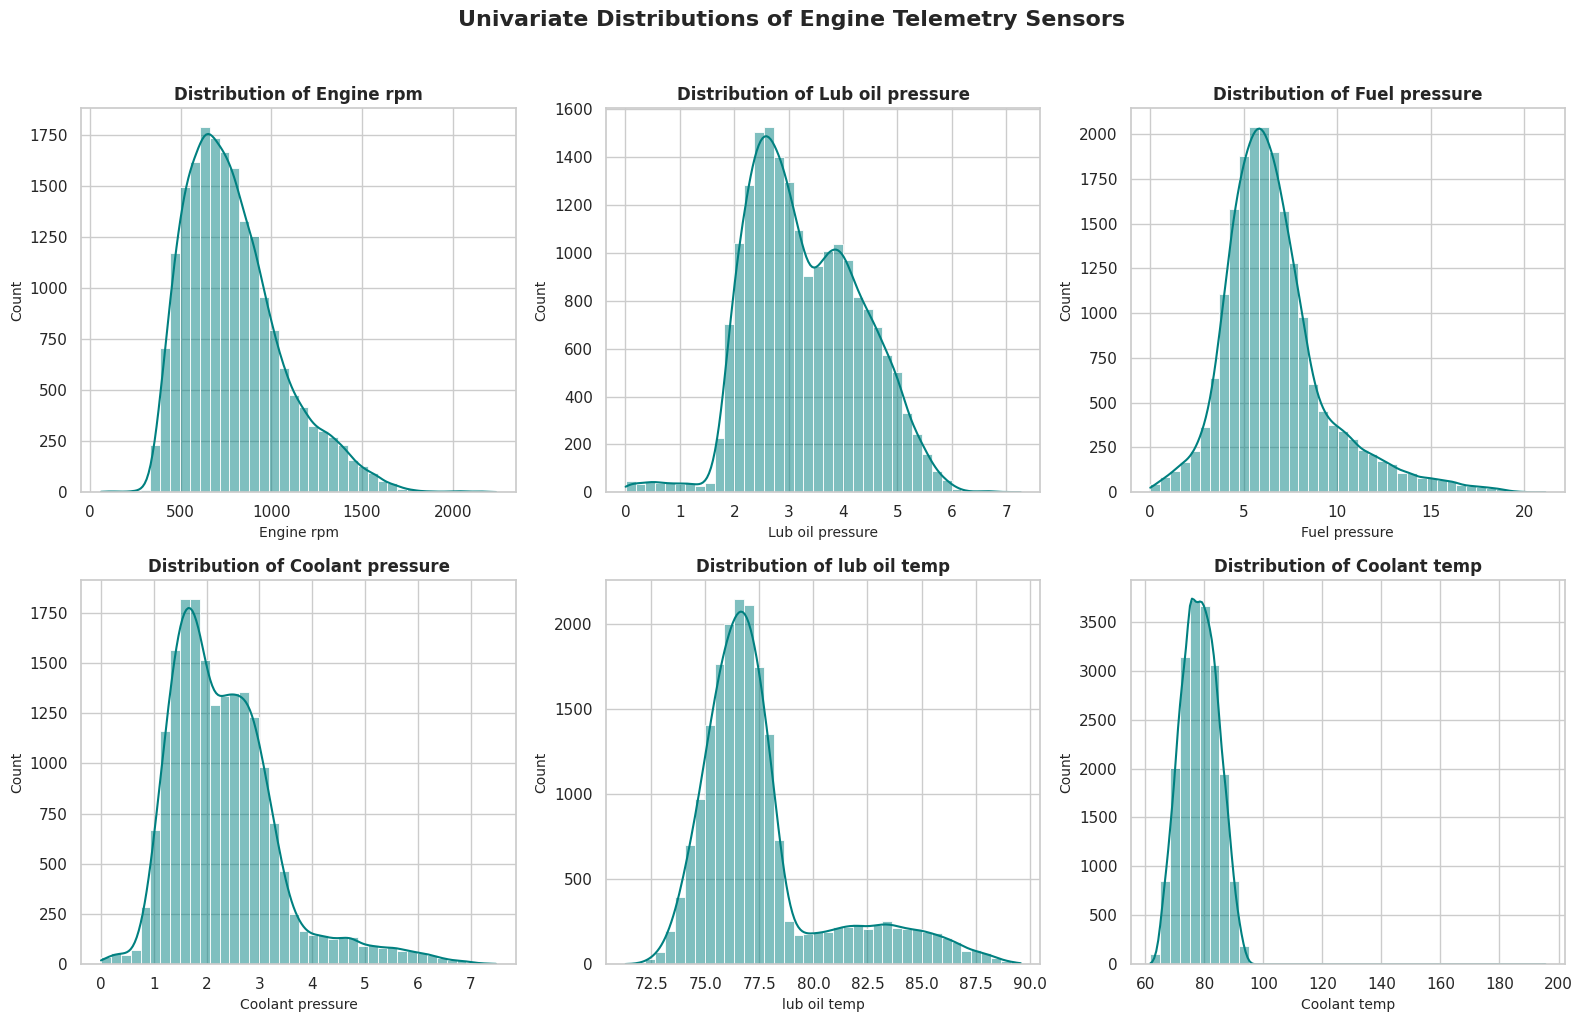


--- Detailed Univariate Shape Analysis ---


,Feature,Skewness,Kurtosis,Mean,Median (50%),Min,Max
0,Engine rpm,0.934932,0.936921,791.239263,746.000000,61.000000,2239.000000
1,Lub oil pressure,0.195783,-0.260152,3.303775,3.162035,0.003384,7.265566
2,Fuel pressure,1.216387,2.452666,6.655615,6.201720,0.003187,21.138326
3,Coolant pressure,1.309420,2.556044,2.335369,2.166883,0.002483,7.478505
4,lub oil temp,1.496375,1.749363,77.643420,76.817350,71.321974,89.580796
5,Coolant temp,0.404451,5.880549,78.427433,78.346662,61.673325,195.527912


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set plotting style
sns.set_theme(style="whitegrid")
cols = ['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp']

# Set up the visualization grid
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for i, col in enumerate(cols):
    row, col_idx = divmod(i, 3)
    sns.histplot(df[col], kde=True, ax=axes[row, col_idx], color='teal', bins=40)
    axes[row, col_idx].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[row, col_idx].set_xlabel(col, fontsize=10)
    axes[row, col_idx].set_ylabel('Count', fontsize=10)

plt.suptitle('Univariate Distributions of Engine Telemetry Sensors', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Calculate skewness, kurtosis and percentiles to deeply analyze the shape of the distributions
univariate_stats = []
for col in cols:
    univariate_stats.append({
        'Feature': col,
        'Skewness': df[col].skew(),
        'Kurtosis': df[col].kurtosis(),
        'Mean': df[col].mean(),
        'Median (50%)': df[col].median(),
        'Min': df[col].min(),
        'Max': df[col].max()
    })

stats_df = pd.DataFrame(univariate_stats)
print("\n--- Detailed Univariate Shape Analysis ---")
display(stats_df)

### Bivariate Analysis

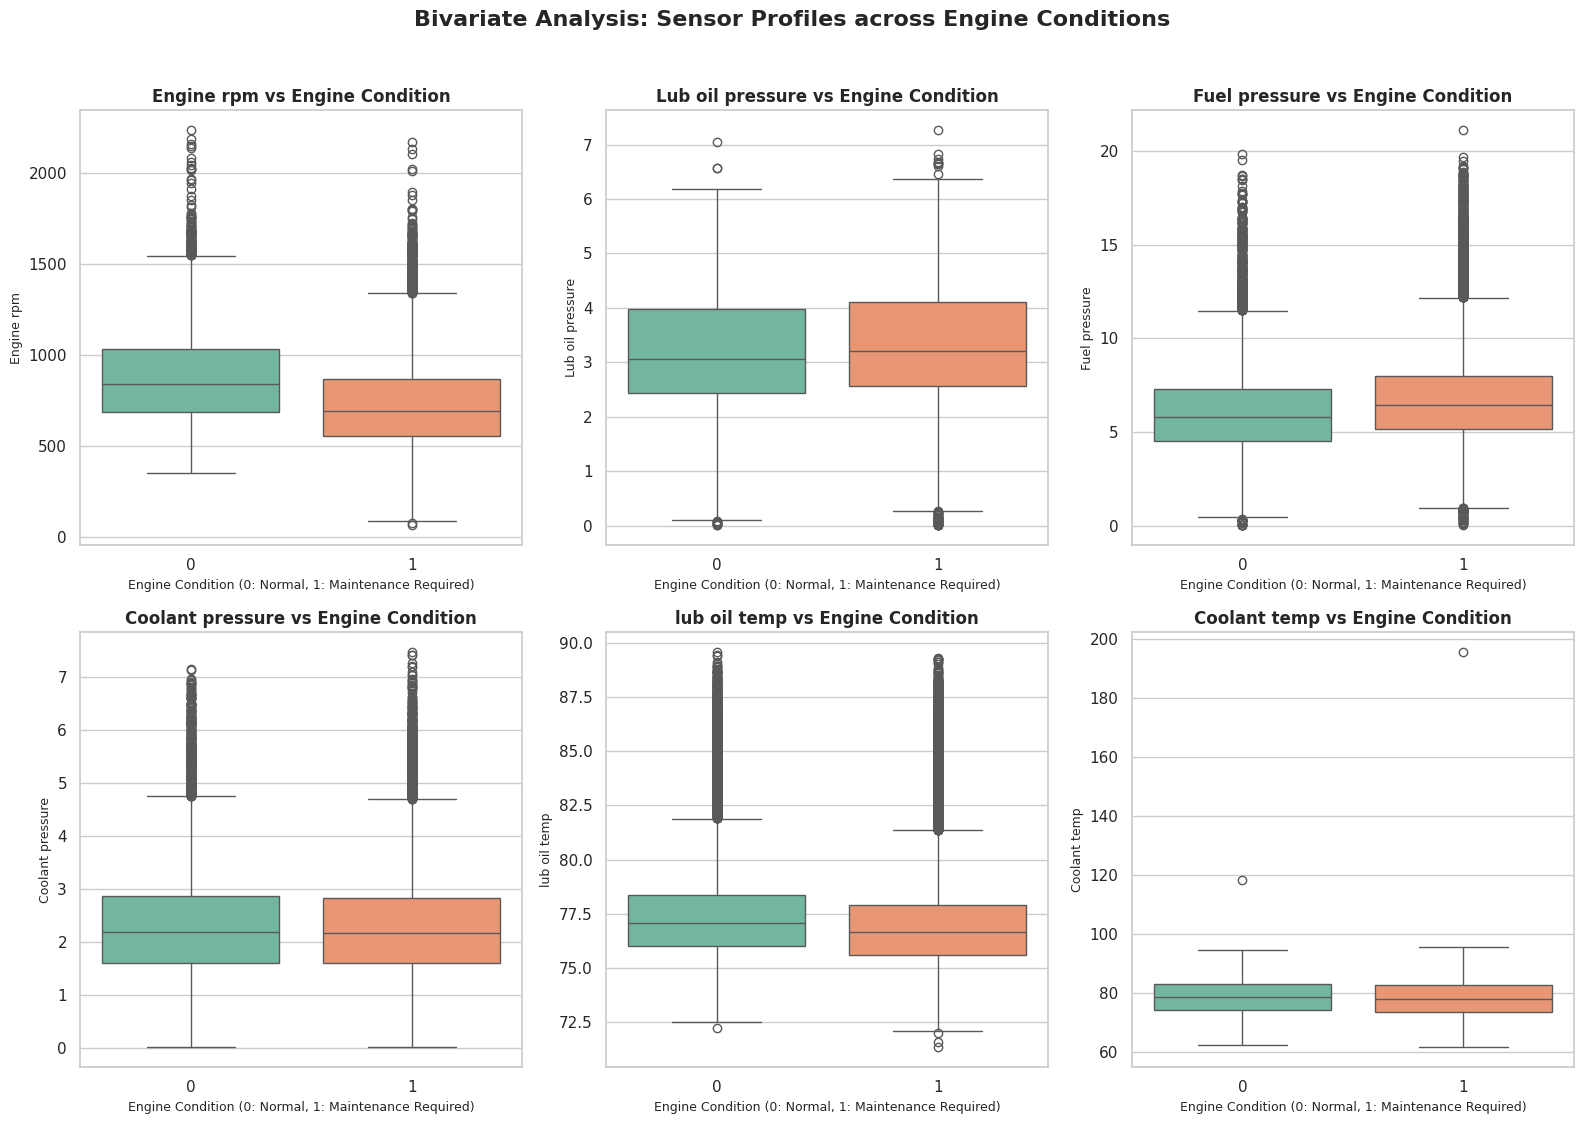


 DESCRIPTIVE STATISTICS BY ENGINE CONDITION (BIVARIATE PROFILES)

Sensor: Engine rpm


,mean,median,std,min,max
Engine Condition,,,,,
0,884.995012,843.0,271.722814,351,2239
1,736.296582,690.0,249.302159,61,2172



Sensor: Lub oil pressure


,mean,median,std,min,max
Engine Condition,,,,,
0,3.222497,3.067195,1.010354,0.007891,7.051322
1,3.351406,3.214466,1.025252,0.003384,7.265566



Sensor: Fuel pressure


,mean,median,std,min,max
Engine Condition,,,,,
0,6.236310,5.824090,2.681545,0.003187,19.858917
1,6.901337,6.420928,2.777391,0.050703,21.138326


... (2 outputs left out)


Sensor: lub oil temp


,mean,median,std,min,max
Engine Condition,,,,,
0,78.023934,77.089781,3.231807,72.244554,89.580796
1,77.420432,76.660067,3.015850,71.321974,89.286302



Sensor: Coolant temp


,mean,median,std,min,max
Engine Condition,,,,,
0,78.803030,78.768801,5.968385,62.445955,118.371957
1,78.207326,78.100543,6.332167,61.673325,195.527912


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configure plotting style for a formal report
sns.set_theme(style="whitegrid")

# 1. Generate descriptive Bivariate Boxplots
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for i, col in enumerate(cols):
    row, col_idx = divmod(i, 3)

    # Using hue to align with modern seaborn standards and avoid warnings
    sns.boxplot(
        x='Engine Condition',
        y=col,
        data=df,
        ax=axes[row, col_idx],
        hue='Engine Condition',
        palette='Set2',
        legend=False
    )
    axes[row, col_idx].set_title(f'{col} vs Engine Condition', fontsize=12, fontweight='bold')
    axes[row, col_idx].set_xlabel('Engine Condition (0: Normal, 1: Maintenance Required)', fontsize=9)
    axes[row, col_idx].set_ylabel(col, fontsize=9)

plt.suptitle('Bivariate Analysis: Sensor Profiles across Engine Conditions', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 2. Extract and print descriptive statistical breakdown for the report
print("\n" + "="*80)
print(" DESCRIPTIVE STATISTICS BY ENGINE CONDITION (BIVARIATE PROFILES)")
print("="*80)

for col in cols:
    stats = df.groupby('Engine Condition')[col].agg(['mean', 'median', 'std', 'min', 'max'])
    print(f"\nSensor: {col}")
    display(stats)

### Multivariate analysis

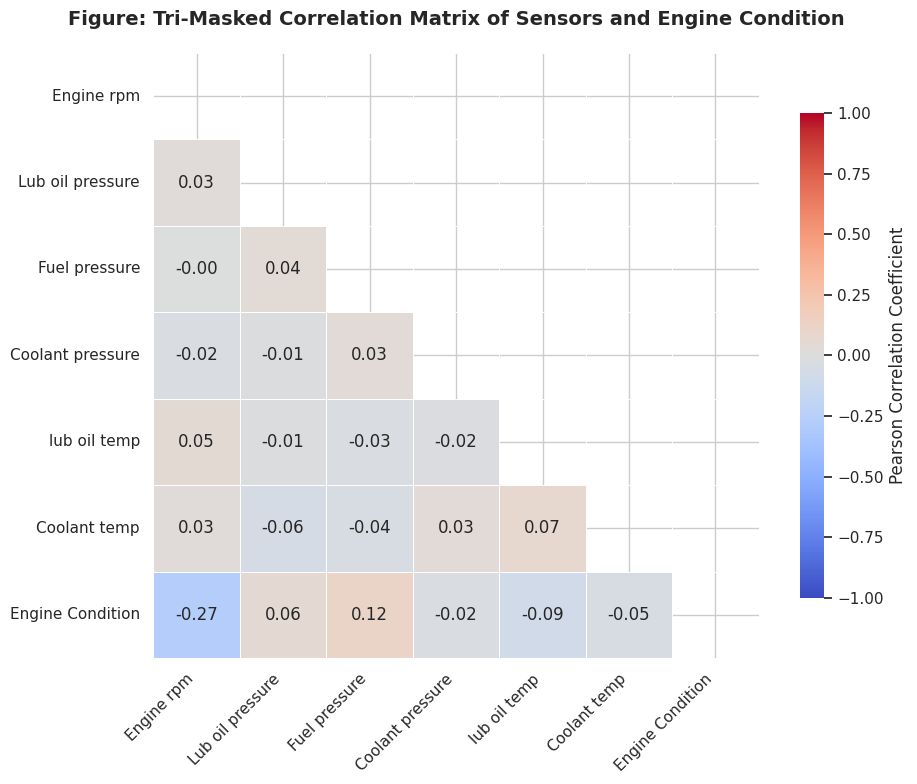


 MULTIVARIATE INTERPRETATION & INSIGHTS REPORT

1. Correlation with Target (Engine Condition):
   * Fuel pressure      : +0.1163 (positive linear relationship with failure state)
   * Lub oil pressure   : +0.0609 (positive linear relationship with failure state)
   * Coolant pressure   : -0.0241 (negative linear relationship with failure state)
   * Coolant temp       : -0.0463 (negative linear relationship with failure state)
   * lub oil temp       : -0.0936 (negative linear relationship with failure state)
   * Engine rpm         : -0.2682 (negative linear relationship with failure state)

2. Notable Inter-Sensor Relationships:
   * Engine Condition and Engine rpm: -0.2682
   * Engine Condition and Fuel pressure: +0.1163


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Calculate correlation matrix
corr_matrix = df.corr()

# Generate a mask for the upper triangle to make it publication-ready
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Configure figure styling
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    vmin=-1.0,
    vmax=1.0,
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)

plt.title('Figure: Tri-Masked Correlation Matrix of Sensors and Engine Condition', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Generate descriptive analysis summary for the project report
print("\n" + "="*80)
print(" MULTIVARIATE INTERPRETATION & INSIGHTS REPORT")
print("="*80)

# Highlight correlation with the target variable
target_corr = corr_matrix['Engine Condition'].drop('Engine Condition').sort_values(ascending=False)
print("\n1. Correlation with Target (Engine Condition):")
for idx, val in target_corr.items():
    direction = "positive" if val > 0 else "negative"
    print(f"   * {idx:<18} : {val:+.4f} ({direction} linear relationship with failure state)")

# Highlight strongest collinearity pairs among sensors
corr_tri = corr_matrix.where(~mask).stack().reset_index()
corr_tri.columns = ['Feature 1', 'Feature 2', 'Correlation']
strong_pairs = corr_tri[corr_tri['Correlation'].abs() >= 0.1].sort_values(by='Correlation', key=abs, ascending=False)

print("\n2. Notable Inter-Sensor Relationships:")
if not strong_pairs.empty:
    for _, row in strong_pairs.iterrows():
        print(f"   * {row['Feature 1']} and {row['Feature 2']}: {row['Correlation']:+.4f}")
else:
    print("   * No strong multicollinearity detected among raw sensors (all Pearson coefficients |r| < 0.1).")

## Feature Engineering & Preprocessing

### Feature engineering

In [7]:
import numpy as np
import pandas as pd

def engineer_features(df_input):
    """
    Engineers predictive maintenance features by calculating
    sensor ratios and thermal/pressure differentials.
    """
    df_feat = df_input.copy()

    # 1. Oil Pressure to RPM Ratio (Indicates lubrication efficiency relative to engine speed)
    df_feat['Oil_Pressure_to_RPM_Ratio'] = df_feat['Lub oil pressure'] / (df_feat['Engine rpm'] + 1e-5)

    # 2. Fuel Pressure to RPM Ratio (Indicates fuel delivery efficiency per RPM)
    df_feat['Fuel_Pressure_to_RPM_Ratio'] = df_feat['Fuel pressure'] / (df_feat['Engine rpm'] + 1e-5)

    # 3. Coolant Pressure to RPM Ratio
    df_feat['Coolant_Pressure_to_RPM_Ratio'] = df_feat['Coolant pressure'] / (df_feat['Engine rpm'] + 1e-5)

    # 4. Thermal Differential (Coolant Temperature minus Lubricating Oil Temperature)
    df_feat['Thermal_Diff'] = df_feat['Coolant temp'] - df_feat['lub oil temp']

    print(f"Original feature count: {df_input.shape[1]}")
    print(f"Expanded feature count after engineering: {df_feat.shape[1]}")

    return df_feat

# Apply feature engineering on our dataset
df_modeled = engineer_features(df_engine)
display(df_modeled.head())

Original feature count: 7
Expanded feature count after engineering: 11


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition,Oil_Pressure_to_RPM_Ratio,Fuel_Pressure_to_RPM_Ratio,Coolant_Pressure_to_RPM_Ratio,Thermal_Diff
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1,0.003562,0.016844,0.004541,-2.511976
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0,0.003358,0.018486,0.002813,4.804790
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1,0.005696,0.012602,0.002047,1.893511
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1,0.007839,0.041248,0.007880,-2.355278
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0,0.009165,0.025426,0.003315,8.603237


### Outlier Handling Strategy: Preservation over Removal
**Observation:** Extreme sensor readings—such as coolant temperatures reaching 195.5°C or high-pressure spikes—were highlighted during univariate and bivariate analysis.

**Domain Rationale:** In predictive maintenance, extreme readings are rarely data entry errors; instead, they represent true failure signatures, thermal runaways, or system degradation.

**Action:** We will preserve these outliers rather than clipping or dropping them. Tree-based algorithms (Random Forest, XGBoost) naturally isolate splits that capture these rare failure thresholds without being distorted.



### Model Selection Rationale for Predictive Maintenance

**Tree-Based Ensembles (Random Forest, XGBoost):** Recommended as primary models. They handle non-linear decision boundaries, are invariant to monotonic feature scaling, and capture interaction terms (e.g., high temperature combined with low oil pressure) automatically.

**Feature Scaling:** Not required for tree-based architectures, preserving the raw interpretability of physical sensor units (Bar, RPM, °C).

## Model Building

### Train-Test splitting
We use a stratified split to ensure that the class distribution of **Engine Condition** remains consistent across both sets.

In [8]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Separate Features (X) and Target (y)
X = df.drop(columns=['Engine Condition'])
y = df['Engine Condition']

# Perform Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Recombine features and target for saving
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

# Save Locally to Artifacts Directory
artifact_dir = os.path.join("predictive_maintenance_project", "artifacts")
os.makedirs(artifact_dir, exist_ok=True)

train_path = os.path.join(artifact_dir, "train.csv")
test_path = os.path.join(artifact_dir, "test.csv")

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

print(f"--- Data Split Summary ---")
print(f"Training Set saved to: {train_path} | Shape: {train_df.shape}")
print(f"Testing Set saved to: {test_path} | Shape: {test_df.shape}")

print("\nTraining Class Distribution:")
print(train_df['Engine Condition'].value_counts(normalize=True) * 100)

print("\nTesting Class Distribution:")
print(test_df['Engine Condition'].value_counts(normalize=True) * 100)

--- Data Split Summary ---
Training Set saved to: predictive_maintenance_project/artifacts/train.csv | Shape: (15628, 7)
Testing Set saved to: predictive_maintenance_project/artifacts/test.csv | Shape: (3907, 7)

Training Class Distribution:
Engine Condition
1    63.053494
0    36.946506
Name: proportion, dtype: float64

Testing Class Distribution:
Engine Condition
1    63.040696
0    36.959304
Name: proportion, dtype: float64


### Experimentation tracking

* Define a model and parameters
* Tune the model with the defined parameters
* Log all tuned parameters
* Evaluate model performance
* Save the best model so the pipeline can commit it to the repository

In [9]:
import os
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier
)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Load train and test sets from workflow artifacts
train_path = os.path.join("predictive_maintenance_project", "artifacts", "train.csv")
test_path = os.path.join("predictive_maintenance_project", "artifacts", "test.csv")

if not os.path.exists(train_path) or not os.path.exists(test_path):
    raise FileNotFoundError("Train or test artifact files not found. Please run the data splitting step first.")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

X_train = train_df.drop(columns=['Engine Condition'])
y_train = train_df['Engine Condition']

X_test = test_df.drop(columns=['Engine Condition'])
y_test = test_df['Engine Condition']

print(f"Loaded Training Data: {X_train.shape}")
print(f"Loaded Testing Data: {X_test.shape}")

# 2. Define candidate models for experimentation
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Bagging": BaggingClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 3. Train and evaluate all candidate models
experiment_results = []
trained_models = {}

print("\n--- Training & Evaluating Candidate Models ---")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)

    experiment_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })
    trained_models[name] = model
    print(f"Finished evaluating {name} -> F1-Score: {f1:.4f} | ROC-AUC: {roc_auc:.4f}")

# 4. Display Experimentation Leaderboard
results_df = pd.DataFrame(experiment_results).sort_values(by="F1-Score", ascending=False)
print("\n--- Model Experimentation Leaderboard ---")
display(results_df.reset_index(drop=True))

# 5. Select Best Model & Perform Hyperparameter Tuning
best_model_name = results_df.iloc[0]["Model"]
print(f"\nTop performing model selected for tuning: {best_model_name}")

# Hyperparameter tuning for AdaBoost (top performer)
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 1.0]
}

grid_search = GridSearchCV(
    estimator=AdaBoostClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
print(f"Best Tuned Parameters: {grid_search.best_params_}")

best_tuned_model = grid_search.best_estimator_

# Final Evaluation of Tuned Model
y_pred_tuned = best_tuned_model.predict(X_test)
print("\n--- Tuned Best Model Test Performance ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

# 6. Save Best Model Locally for Repository Commit
model_dir = os.path.join("predictive_maintenance_project", "models")
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "best_engine_model.pkl")

joblib.dump(best_tuned_model, model_path)
print(f"\nBest model successfully saved to repository directory: {model_path}")

Loaded Training Data: (15628, 6)
Loaded Testing Data: (3907, 6)

--- Training & Evaluating Candidate Models ---
Finished evaluating Decision Tree -> F1-Score: 0.6793 | ROC-AUC: 0.5610
Finished evaluating Bagging -> F1-Score: 0.6993 | ROC-AUC: 0.6407
Finished evaluating Random Forest -> F1-Score: 0.7393 | ROC-AUC: 0.6773
Finished evaluating AdaBoost -> F1-Score: 0.7504 | ROC-AUC: 0.6911
Finished evaluating Gradient Boosting -> F1-Score: 0.7603 | ROC-AUC: 0.7035

--- Model Experimentation Leaderboard ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.664704,0.691975,0.843687,0.760337,0.703489
1,AdaBoost,0.657026,0.693287,0.817702,0.750373,0.691053
2,Random Forest,0.645252,0.688749,0.797808,0.739278,0.677300
3,Bagging,0.618889,0.695740,0.702801,0.699253,0.640720
4,Decision Tree,0.593038,0.674950,0.683719,0.679306,0.561042



Top performing model selected for tuning: Gradient Boosting
Best Tuned Parameters: {'learning_rate': 0.01, 'n_estimators': 50}

--- Tuned Best Model Test Performance ---
Accuracy:  0.6304
Precision: 0.6304
Recall:    1.0000
F1-Score:  0.7733

Best model successfully saved to repository directory: predictive_maintenance_project/models/best_engine_model.pkl


### Feature importance analysis
Extract and plot feature importances (e.g., which sensor—RPM, oil pressure, or temperature—is the strongest predictor of failure?)
These cells will train a Random Forest Classifier—an ideal algorithm for this task because it inherently handles non-linear relationships and outputs clear feature importances—and then visualize the results.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Define your features (X) and target variable (y)
# Drop non-feature columns like IDs, timestamps, or the target column itself
X = df.drop(columns=['Engine Condition', 'Engine_ID', 'Timestamp'], errors='ignore')
y = df['Engine Condition']

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Evaluate model performance on the test set
y_pred = rf_model.predict(X_test)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.39      0.45      1444
           1       0.69      0.80      0.74      2463

    accuracy                           0.65      3907
   macro avg       0.61      0.59      0.59      3907
weighted avg       0.63      0.65      0.63      3907



/tmp/ipykernel_4990/3420835264.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


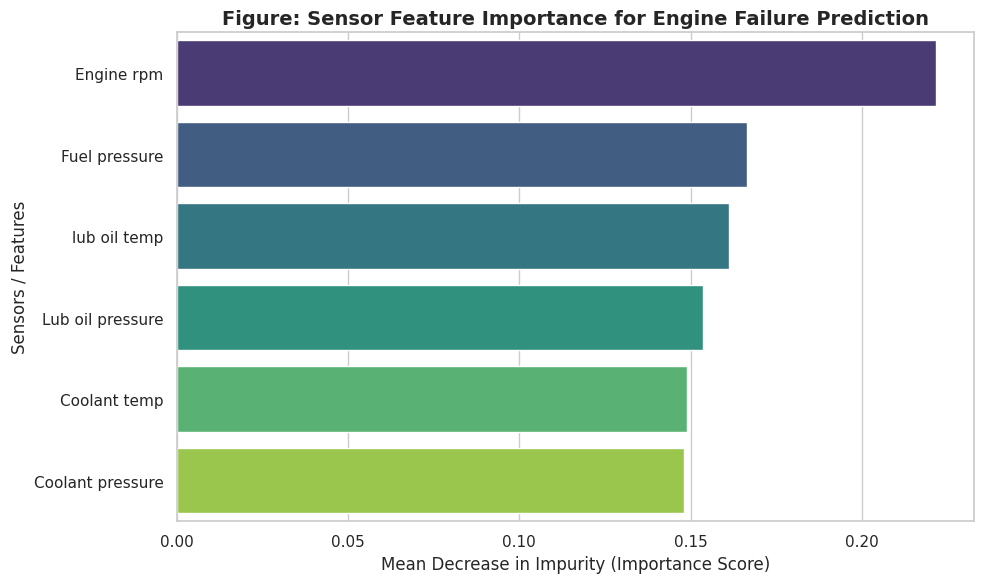

Top Predictive Features:


,Feature,Importance
0,Engine rpm,0.221614
2,Fuel pressure,0.166464
4,lub oil temp,0.161281
1,Lub oil pressure,0.153554
5,Coolant temp,0.149051
3,Coolant pressure,0.148036



Most Important Feature: Engine rpm (Importance Score: 0.2216)


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract feature importances from the trained model
importances = rf_model.feature_importances_
feature_names = X.columns

# Create a sorted DataFrame for clean plotting and inspection
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Configure plot styling
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')

# Add titles, labels, and formatting
plt.title('Figure: Sensor Feature Importance for Engine Failure Prediction', fontsize=14, fontweight='bold')
plt.xlabel('Mean Decrease in Impurity (Importance Score)', fontsize=12)
plt.ylabel('Sensors / Features', fontsize=12)
plt.tight_layout()
plt.show()

# Display the numerical breakdown
print("Top Predictive Features:")
display(feature_importance_df.head(10))

# Identify and print the most important feature based on analysis results
most_important_feature = feature_importance_df.iloc[0]['Feature']
most_important_value = feature_importance_df.iloc[0]['Importance']
print(f"\nMost Important Feature: {most_important_feature} (Importance Score: {most_important_value:.4f})")

### Reconcile feature importance with experimentation tracking and train-test split


| Step | Phase | Core Action | Best Practice / Rule |
| :--- | :--- | :--- | :--- |
| **1** | **Data Ingestion & Cleaning** | Load raw telemetry data, handle missing values, drop corrupt records, and define your target variable (`Engine Condition`). | Clean the dataset holistically before splitting, but ensure no transformation relies on test set distribution. |
| **2** | **Train-Test Split** | Partition data into training (e.g., 80%) and testing (20%) sets. | **Must be done first.** The test set must remain entirely untouched and unseen until final model evaluation to prevent data leakage. |
| **3** | **Model Building & Training** | Initialize your classifier (e.g., Random Forest) and fit it to the dataset. | Train the model **exclusively** on the training partition. |
| **4** | **Feature Importance Extraction** | Extract impurity-based feature importances (`feature_importances_`) from the trained model. | Analyze which sensors (RPM, oil pressure, etc.) drive predictions to guide subsequent iterations. |
| **5** | **Experimentation Tracking** | Log hyperparameters, evaluation metrics (F1-score, precision/recall), and feature importance visual artifacts. | Use an experiment tracker (e.g., MLflow, Weights & Biases) to maintain reproducibility across runs. |

## 4. Business Impact & Maintenance Scheduling Policy

While high model accuracy is a strong technical indicator, deploying a predictive maintenance model requires balancing the operational costs of **False Positives** (unnecessary maintenance downtime) against **False Negatives** (missed engine failures leading to catastrophic breakdowns).

To operationalize our model outputs, we translate precision and recall into a three-tier risk-based maintenance scheduling policy.

### **4.1 Translating Statistical Metrics to Operational Reality**
* **Recall (Minimizing False Negatives):** In engine maintenance, a false negative means failing to predict an impending breakdown. This results in catastrophic failure, extensive collateral equipment damage, and high emergency repair costs. Therefore, our policy prioritizes a **high recall threshold** for critical failure modes, ensuring that maximum potential failures are flagged early.
* **Precision (Minimizing False Positives):** A false positive occurs when a healthy engine is flagged for maintenance, causing unnecessary downtime and squandering technician labor and replacement parts. By tuning the model's decision threshold based on precision curves, we minimize "ghost alarms" to maintain operational efficiency and crew trust in the automated system.

---

### **4.2 Actionable Maintenance Policies**

Based on the model's probabilistic output scores, maintenance operations should be segmented into three distinct protocols:

| Risk Tier | Model Probability Score | Operational Status | Required Action & Protocol |
| :--- | :--- | :--- | :--- |
| **Tier 1: Critical Risk** | $> 0.80$ Probability of Failure | **Immediate Shutdown / Inspection** | Route engine to maintenance bay immediately. Halt operations to prevent catastrophic failure. Replace high-importance sensors or components identified by feature importance analysis. |
| **Tier 2: Moderate Risk** | $0.40 - 0.80$ Probability of Failure | **Scheduled Condition Monitoring** | Flag for priority inspection during the next scheduled operational window (e.g., end-of-shift or weekend). Increase telemetry logging frequency for dominant predictor variables (e.g., oil pressure and temperature). |
| **Tier 3: Low Risk** | $< 0.40$ Probability of Failure | **Routine Maintenance** | Maintain standard operating procedures. No immediate intervention required; follow regular scheduled maintenance intervals. |

---

### **4.3 Recommendations for Deployment & Iteration**
1. **Dynamic Threshold Tuning:** Rather than relying on a static 0.5 classification threshold, tune the decision threshold using a cost-benefit matrix that weighs the exact dollar cost of an emergency breakdown versus a scheduled inspection.
2. **Sensor-Driven Monitoring:** Because feature importance analysis highlights specific telemetry metrics (e.g., oil pressure drops or abnormal thermal spikes) as primary drivers of failure, plant engineers should configure real-time hardware alerts specifically for these leading indicators.
3. **Continuous Feedback Loop:** Log whether flagged engines actually required repairs when opened up by technicians. Feed these verification logs back into the training pipeline to retrain the model and reduce false positives over time.

## 5. Model Deployment with Streamlit

This section creates a Streamlit app that loads the **tuned model already saved by the experimentation-tracking cell**, collects sensor readings, stores the submitted inputs in a pandas DataFrame, and displays predictions. The app does not train a model or require the training dataset at startup.

**Prerequisite:** Run the data-loading, train-test splitting, and experimentation-tracking cells first, in the same Python environment used below. Saved notebook outputs alone do not create the model file. The required artifact is `predictive_maintenance_project\models\best_engine_model.pkl`.

The saved tuned model was trained on the **six raw sensor columns**, not on `df_modeled`. Do not add engineered ratios, scaling, or the target column to the app's prediction inputs unless the model is retrained with the corresponding preprocessing pipeline.

### 5.1 Verify the saved model and its input schema

Load only the trusted model produced by this notebook. Pickle/joblib files can execute code when loaded; never load an arbitrary uploaded model. A scikit-learn version mismatch is treated as an error so that incompatible artifacts are not silently deployed.

In [ ]:
from pathlib import Path
import warnings
import joblib
from sklearn.exceptions import InconsistentVersionWarning

deployment_dir = Path("predictive_maintenance_project")
deployment_model_path = deployment_dir.joinpath("models", "best_engine_model.pkl")

if not deployment_model_path.is_file():
    raise FileNotFoundError(
        f"Model not found: {deployment_model_path}. "
        "Run the experimentation-tracking cell to train and save the tuned model first."
    )

with warnings.catch_warnings():
    warnings.simplefilter("error", InconsistentVersionWarning)
    deployment_model = joblib.load(deployment_model_path)

if not hasattr(deployment_model, "feature_names_in_"):
    raise ValueError("Save a model fitted on a DataFrame with named sensor columns.")

deployment_feature_columns = list(deployment_model.feature_names_in_)
print(f"Saved model: {type(deployment_model).__name__}")
print(f"Prediction columns, in training order: {deployment_feature_columns}")
print(f"Engine Condition class labels: {deployment_model.classes_.tolist()}")

### 5.2 Create the Streamlit application

Run the following cell to write `streamlit_app.py` into the project folder. The model path is resolved relative to the app file, so it works locally and on Community Cloud. The cache key includes the model file's path and modification time, so an artifact replaced by the automated workflow is reloaded on the next rerun. Inputs are ordered using the saved model's `feature_names_in_`.

RPM and pressures cannot be negative; temperatures have no artificial lower bound. No upper limits are imposed, because unusually high readings may be genuine failure signals. The latest submitted DataFrame and prediction are retained in the user's Streamlit session and can be downloaded as CSV.

The notebook does not establish whether target label `0` or `1` means failure. The app therefore displays the original class label and class-specific probabilities instead of assuming a healthy/faulty mapping.

In [ ]:
app_code = r'''
from pathlib import Path
from pickle import UnpicklingError
import warnings

import joblib
import numpy as np
import pandas as pd
import streamlit as st
from sklearn.exceptions import InconsistentVersionWarning

st.set_page_config(page_title="Engine Predictive Maintenance", layout="centered")
st.title("Engine Predictive Maintenance")
st.caption("Enter sensor readings to use the tuned model saved by the notebook.")

MODEL_PATH = Path(__file__).resolve().parent.joinpath("models", "best_engine_model.pkl")
INPUT_SETTINGS = {
    "Engine rpm": {"label": "Engine speed (RPM)", "value": 900.0, "step": 10.0, "min_value": 0.0},
    "Lub oil pressure": {"label": "Lubricating oil pressure (bar)", "value": 3.0, "step": 0.1, "min_value": 0.0},
    "Fuel pressure": {"label": "Fuel pressure (bar)", "value": 6.0, "step": 0.1, "min_value": 0.0},
    "Coolant pressure": {"label": "Coolant pressure (bar)", "value": 2.0, "step": 0.1, "min_value": 0.0},
    "lub oil temp": {"label": "Lubricating oil temperature (degrees C)", "value": 78.0, "step": 0.1},
    "Coolant temp": {"label": "Coolant temperature (degrees C)", "value": 80.0, "step": 0.1},
}


@st.cache_resource
def load_model(model_file: str, model_revision: int):
    # The revision participates in Streamlit's cache key when CI replaces the model.
    with warnings.catch_warnings():
        warnings.simplefilter("error", InconsistentVersionWarning)
        return joblib.load(model_file)


try:
    if not MODEL_PATH.is_file():
        raise FileNotFoundError(
            "Missing models/best_engine_model.pkl. Commit the model saved by the notebook."
        )
    model = load_model(str(MODEL_PATH), MODEL_PATH.stat().st_mtime_ns)
except (OSError, ImportError, ValueError, EOFError, UnpicklingError, InconsistentVersionWarning) as error:
    st.error(f"Unable to load the committed model: {error}")
    st.stop()

if not hasattr(model, "feature_names_in_"):
    st.error("The saved model must be fitted on a DataFrame with named sensor columns.")
    st.stop()

feature_columns = list(model.feature_names_in_)
if len(feature_columns) != len(INPUT_SETTINGS) or set(feature_columns) != set(INPUT_SETTINGS):
    st.error("The committed model's input schema does not match the six raw sensor inputs.")
    st.stop()

with st.form("engine_sensor_form"):
    columns = st.columns(2)
    sensor_inputs = {}
    for index, (feature, settings) in enumerate(INPUT_SETTINGS.items()):
        with columns[index % 2]:
            sensor_inputs[feature] = st.number_input(key=feature, **settings)
    submitted = st.form_submit_button("Predict engine condition")

if submitted:
    input_df = pd.DataFrame([sensor_inputs], columns=feature_columns)
    if not np.isfinite(input_df.to_numpy(dtype=float)).all():
        st.error("All sensor readings must be finite numbers.")
        st.stop()

    try:
        predicted_condition = model.predict(input_df)[0]
        class_probabilities = model.predict_proba(input_df)[0]
    except (ValueError, TypeError) as error:
        st.error(f"Prediction failed: {error}")
        st.stop()

    st.session_state["input_df"] = input_df
    st.session_state["predicted_condition"] = str(predicted_condition)
    st.session_state["class_probabilities"] = pd.DataFrame({
        "Engine Condition": [str(label) for label in model.classes_],
        "Probability": class_probabilities,
    })

if "input_df" in st.session_state:
    st.subheader("Latest submitted sensor readings")
    st.dataframe(st.session_state["input_df"], hide_index=True)
    st.metric("Predicted Engine Condition", st.session_state["predicted_condition"])
    st.subheader("Model probabilities by class")
    st.dataframe(st.session_state["class_probabilities"], hide_index=True)
    st.caption(
        "Confirm the dataset's class-label mapping before interpreting a label as healthy or faulty. "
        "Model scores are not calibrated failure-risk estimates or automatic maintenance instructions."
    )
    st.download_button(
        "Download submitted inputs (CSV)",
        data=st.session_state["input_df"].to_csv(index=False).encode("utf-8"),
        file_name="engine_inputs.csv",
        mime="text/csv",
    )
'''

deployment_dir.mkdir(parents=True, exist_ok=True)
deployment_app_path = deployment_dir.joinpath("streamlit_app.py")
deployment_app_path.write_text(app_code.strip() + "\n", encoding="utf-8")
print(f"Streamlit app written to: {deployment_app_path.resolve()}")

### 5.3 Define the deployment dependencies

Run this cell in the **same kernel that trained and saved the model**. It creates `requirements.txt`, pinning pandas, NumPy, SciPy, scikit-learn, and joblib to the installed training-environment versions. Streamlit is restricted to its compatible major version.

This app needs no `google-colab`, plotting libraries, training CSVs, or `packages.txt`. Standard-library modules such as `pathlib`, `pickle`, and `warnings` must not be listed as pip dependencies. Use the Python major/minor version printed below when configuring Community Cloud.

In [ ]:
from importlib.metadata import version
import sys

deployment_dependencies = ["streamlit>=1.40,<2"]
for package_name in ("pandas", "numpy", "scipy", "scikit-learn", "joblib"):
    deployment_dependencies.append(f"{package_name}=={version(package_name)}")

deployment_requirements = "\n".join(deployment_dependencies) + "\n"
deployment_requirements_path = deployment_dir.joinpath("requirements.txt")
deployment_requirements_path.write_text(deployment_requirements, encoding="utf-8")

print(f"Dependencies written to: {deployment_requirements_path.resolve()}")
print(deployment_requirements)
print(f"Select Python {sys.version_info.major}.{sys.version_info.minor} in Community Cloud Advanced settings.")

### 5.4 Set up and test the app locally

1. Run sections **5.1, 5.2, and 5.3** in order. They verify the saved model and generate the application and dependencies.
2. Keep the following deployment layout. Use `predictive_maintenance_project` as the GitHub repository root:

   ```text
   predictive_maintenance_project\
       streamlit_app.py
       requirements.txt
       models\
           best_engine_model.pkl
   ```

   If training in Google Colab, use the **Files** sidebar to download these three files, then recreate this layout on your computer. Do not copy the `data` or `artifacts` folders into the deployment repository.
3. Open a terminal in the project folder. With the same Python major/minor version as the training kernel, run the following **Windows PowerShell** commands:

   ```powershell
   Set-Location "C:\path\to\predictive_maintenance_project"
   python -m venv .venv
   .\.venv\Scripts\python.exe -m pip install -r requirements.txt
   .\.venv\Scripts\python.exe -m streamlit run streamlit_app.py
   ```

   Calling the virtual environment's Python directly avoids PowerShell activation-policy issues. On macOS/Linux, use the equivalent `.venv` Python executable.
4. Open **http://localhost:8501**, enter all six sensor readings, and select **Predict engine condition**. Check that the submitted DataFrame has one row and six columns, that a class label and class probabilities appear, and that **Download submitted inputs (CSV)** produces those same sensor readings.
5. Stop the local app with **Ctrl+C** when finished. The DataFrame is session-only: it is not a permanent database and is lost when the session ends. Download the CSV to retain it; use an external database if durable multi-user logging is later required.

### 5.5 Deploy on Streamlit Community Cloud

1. Create a GitHub repository for the app. Only publish a model you are permitted to share. Commit `streamlit_app.py`, `requirements.txt`, and `models\best_engine_model.pkl`, preserving the layout above. Keep raw datasets, train/test CSVs, `.venv`, and secrets out of the repository.
2. One way to upload the files is to use Git from the project folder. Replace the repository URL with your own newly created, empty GitHub repository. If this is already a Git repository, use its existing branch and remote instead of initializing another repository:

   ```powershell
   git init -b main
   git add streamlit_app.py requirements.txt models\best_engine_model.pkl
   git commit -m "Add predictive maintenance Streamlit app"
   git remote add origin https://github.com/YOUR_USERNAME/predictive-maintenance.git
   git push -u origin main
   ```

   You can also upload the files through GitHub's browser interface; ensure the model is inside the `models` folder rather than at the repository root.
3. Sign in to **https://share.streamlit.io** and connect/authorize your GitHub account so Community Cloud can access the repository.
4. Select **Create app**, then **Yup, I have an app**. Choose your repository and branch (for example, `main`), and set **Main file path** to `streamlit_app.py`.
5. Open **Advanced settings** and select the **same Python major/minor version printed in section 5.3**. This app does not require secrets. If the training Python version is no longer supported by Community Cloud, retrain and regenerate the model and dependency file in a supported version rather than silently switching versions.
6. Select **Deploy**. Community Cloud installs `requirements.txt` and launches the app. Inspect the build/app logs if installation or model loading fails.
7. Open the generated `https://<your-app-name>.streamlit.app` URL, submit test sensor readings, and verify the prediction, displayed input DataFrame, probabilities, and CSV download before sharing the link.

**If keeping the entire notebook project in a larger repository:** Set the main file path to `predictive_maintenance_project/streamlit_app.py` in the Cloud form. Keep `requirements.txt` next to that app and the model in its adjacent `models` folder. The forward slash here is GitHub's repository-path notation, not a Windows terminal path.

GitHub code/dependency updates trigger redeployment. After replacing the model artifact, reboot the app from Community Cloud's management menu to clear its cached model.

**These cells prepare deployment files; they do not authenticate to GitHub, upload your model, or create a live Cloud app automatically. Complete the account/repository steps above to publish it.**

### 5.6 Deployment checks and troubleshooting

| Check / error | What to do |
| :--- | :--- |
| Model file not found | Run the experimentation-tracking cell, then commit the actual `models\best_engine_model.pkl` file. Verify spelling and capitalization; Community Cloud runs on Linux. |
| Missing module or incompatible scikit-learn version | Use the generated dependency file and matching Python version. If the model came from a different environment, regenerate it and `requirements.txt` together. |
| Feature-name/schema mismatch | Use the exact six raw sensor columns and the saved training order. If training changes, update the app and deploy a matching preprocessing pipeline/model together. |
| Build uses the wrong dependency file | Keep `requirements.txt` next to the app and avoid competing dependency manifests in that directory. |
| Prediction interpretation | Confirm the dataset's `Engine Condition` label mapping before connecting the output to the maintenance policy in section 4. Class scores are not necessarily calibrated failure probabilities. |
| Submitted data disappears | Session state is temporary. Download the inputs CSV or add an external data store; do not rely on the Cloud app's local filesystem for durable storage. |

**Official setup references:** [Deploy your app](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy) and [App dependencies](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/app-dependencies).

## 6. Automated GitHub Actions Workflow

This section extends your existing repository: **https://github.com/arvind2221994/predictive-maintenance**. Its `main` branch already contains the Streamlit app, dependency file, and saved model; there is no need to create another repository.

The supplied `predictive_maintenance_project` folder contains the missing pipeline script, tests, `.github\workflows\pipeline.yml`, and README files. The workflow automates dataset validation, preprocessing, splitting, model comparison/tuning, evaluation, app/dependency generation, and publication of validated generated updates to `main`.

**You will commit/push the initial files and configure GitHub/Streamlit yourself. Nothing in this section authenticates to GitHub or pushes files from your notebook automatically.** Only the workflow running inside GitHub Actions performs later automatic bot commits.

**Dataset prerequisite:** Add your real `engine_data.csv` in the repository's `data` folder. Your repository is public, so only commit data you are permitted to publish. No fabricated dataset is supplied. The existing deployed model does not remove the need for training data.

### 6.1 Prepare the existing repository

1. If you already have a local clone, use it. Otherwise run:

   ```powershell
   git clone https://github.com/arvind2221994/predictive-maintenance.git
   Set-Location predictive-maintenance
   ```

2. Copy the **contents** of the supplied `predictive_maintenance_project` folder into that repository root. Merge folders; do not create an extra nested project folder and do not replace the existing `.git` directory.
3. Keep the updated notebook in the repository root as `PredictiveMaintenance.ipynb`. The automated app build reads Section 5's `app_code` string from this saved notebook without executing the Colab upload or plotting cells.
4. Copy your permitted training CSV to `data\engine_data.csv`. Its exact columns are `Engine rpm`, `Lub oil pressure`, `Fuel pressure`, `Coolant pressure`, `lub oil temp`, `Coolant temp`, and `Engine Condition`.
5. Read `README.md` for the complete setup and `data\README.md` for dataset validation rules. RPM/pressures must be finite and non-negative; temperatures are not clipped; the target must contain both numeric labels `0` and `1`, with at least five distinct records per class after deduplication.

The provided workflow targets **Python 3.12**. Use the same version for local training and Community Cloud. If you change Python, update and test all environments together.

In [ ]:
from pathlib import Path

# Set an absolute repository path here if running from a different location.
automation_repo = Path.cwd()
if not automation_repo.joinpath("scripts", "ml_pipeline.py").is_file():
    automation_repo = automation_repo.joinpath("predictive_maintenance_project")

for relative_parts in (
    ("scripts", "ml_pipeline.py"),
    ("tests", "test_pipeline.py"),
    ("PredictiveMaintenance.ipynb",),
    ("requirements.txt",),
):
    required_file = automation_repo.joinpath(*relative_parts)
    if not required_file.is_file():
        raise FileNotFoundError(
            f"Missing {required_file}. Copy the supplied files into your repository "
            "and set automation_repo to its root."
        )

print(f"Pipeline repository root: {automation_repo}")
print("Supply data/engine_data.csv before running the training stages.")

### 6.2 Non-interactive machine-learning stages

GitHub Actions must not run the entire notebook, because its interactive file-upload cells require Google Colab. The supplied `scripts\ml_pipeline.py` exposes these independently logged stages:

| Stage | Machine-learning action | Output / validation |
| :--- | :--- | :--- |
| `prepare` | Read the repository CSV; validate schema, numeric values and class labels; remove duplicates and non-feature columns. | `artifacts\prepared.csv` and a data profile/checksum. Invalid data fails explicitly. |
| `split` | Create a reproducible stratified 80/20 train-test split. | `artifacts\train.csv` and `artifacts\test.csv`. |
| `train` | Compare Decision Tree, Bagging, Random Forest, AdaBoost, and Gradient Boosting using training-only 3-fold F1 cross-validation; tune the actual winning model. | CV/parameter selection report and `models\best_engine_model.pkl`. |
| `evaluate` | Load the newly saved model and evaluate the untouched test partition. | Accuracy, precision, recall, F1, ROC-AUC, dataset checksum, and environment details in `reports\metrics.json`. |
| `build` | Parse Section 5's literal app source from the committed notebook; regenerate the app and pin all six installed dependencies. | `streamlit_app.py` and `requirements.txt`. |
| Tests | Check data validation, train/test separation, model/schema/metric compatibility, Streamlit DataFrame/prediction/CSV behavior, and model-cache refresh. | All checks must pass before publication. |

The automated pipeline intentionally selects/tunes models **without using test-set scores to choose a winner**, and uses the winning model's own parameter grid rather than always tuning AdaBoost. It preserves the app's six raw-feature contract: no engineered ratios or scalers are introduced.

Intermediate datasets stay in the ignored `artifacts` directory. Only app code, dependencies, the saved model, and the evaluation report are uploaded as deployment artifacts.

### 6.3 Define and write `.github\workflows\pipeline.yml`

The following cell writes the complete YAML into the repository's workflow directory. The same file is already included in the supplied project folder.

Relevant pushes to `main`, pull requests targeting `main`, and manual runs trigger training/tests. Repository permissions are read-only during code execution. A separate publishing job obtains write permission **only after success on `main`**, checks that `main` has not advanced, stages four explicit generated files, skips empty commits, and performs a normal non-force push.

Forward slashes in this YAML are GitHub/Linux runner paths. Use the Windows paths shown in the local PowerShell instructions on your computer.

In [ ]:
pipeline_yaml = r'''
name: Predictive maintenance ML pipeline

on:
  push:
    branches: [main]
    paths:
      - PredictiveMaintenance.ipynb
      - streamlit_app.py
      - requirements.txt
      - data/engine_data.csv
      - scripts/**
      - tests/**
      - .github/workflows/pipeline.yml
  pull_request:
    branches: [main]
    paths:
      - PredictiveMaintenance.ipynb
      - streamlit_app.py
      - requirements.txt
      - data/engine_data.csv
      - scripts/**
      - tests/**
      - .github/workflows/pipeline.yml
  workflow_dispatch:

permissions:
  contents: read

concurrency:
  group: predictive-maintenance-${{ github.ref }}
  cancel-in-progress: true

jobs:
  train-test:
    runs-on: ubuntu-latest
    timeout-minutes: 30
    steps:
      - name: Check out repository
        uses: actions/checkout@v6
        with:
          persist-credentials: false

      - name: Set up matching Python version
        uses: actions/setup-python@v6
        with:
          python-version: "3.12"
          cache: pip
          cache-dependency-path: requirements.txt

      - name: Install and check dependencies
        run: |
          python -m pip install -r requirements.txt
          python -m pip check

      - name: Validate, clean, and preprocess the dataset
        run: python scripts/ml_pipeline.py prepare

      - name: Create the stratified train-test split
        run: python scripts/ml_pipeline.py split

      - name: Compare models, tune the winner, and save the model
        run: python scripts/ml_pipeline.py train

      - name: Evaluate on the held-out test set and write metrics
        run: python scripts/ml_pipeline.py evaluate

      - name: Generate app code and pinned deployment dependencies
        run: python scripts/ml_pipeline.py build

      - name: Check Python syntax
        run: python -m compileall -q scripts tests streamlit_app.py

      - name: Test data validation, model outputs, and Streamlit inputs
        run: python -m unittest discover -s tests -v

      - name: Upload validated deployment files
        uses: actions/upload-artifact@v4
        with:
          name: validated-deployment-${{ github.run_id }}
          if-no-files-found: error
          retention-days: 7
          path: |
            streamlit_app.py
            requirements.txt
            models/best_engine_model.pkl
            reports/metrics.json

  update-main:
    needs: train-test
    if: github.ref == 'refs/heads/main' && (github.event_name == 'push' || github.event_name == 'workflow_dispatch')
    runs-on: ubuntu-latest
    timeout-minutes: 5
    permissions:
      contents: write
    steps:
      - name: Check out the exact source commit
        uses: actions/checkout@v6
        with:
          ref: ${{ github.sha }}
          fetch-depth: 0

      - name: Download only this run's validated deployment
        uses: actions/download-artifact@v4
        with:
          name: validated-deployment-${{ github.run_id }}
          path: .

      - name: Commit generated updates and push to main
        shell: bash
        env:
          SOURCE_SHA: ${{ github.sha }}
        run: |
          set -euo pipefail
          git fetch origin main
          if [ "$(git rev-parse origin/main)" != "$SOURCE_SHA" ]; then
            echo "::error::main changed after training. Re-run on the latest main; stale results will not be pushed."
            exit 1
          fi
          git config user.name "github-actions[bot]"
          git config user.email "41898282+github-actions[bot]@users.noreply.github.com"
          git add -- streamlit_app.py requirements.txt models/best_engine_model.pkl reports/metrics.json
          if git diff --cached --quiet; then
            echo "No generated deployment changes to commit."
            exit 0
          else
            diff_status=$?
            if [ "$diff_status" -ne 1 ]; then
              echo "::error::Unable to inspect staged changes; no deployment will be pushed."
              exit "$diff_status"
            fi
          fi
          git commit -m "Update generated app, dependencies, and ML artifacts" -m "Co-authored-by: Copilot <223556219+Copilot@users.noreply.github.com>"
          git push origin HEAD:main
'''

workflow_directory = automation_repo.joinpath(".github", "workflows")
workflow_directory.mkdir(parents=True, exist_ok=True)
automation_workflow_path = workflow_directory.joinpath("pipeline.yml")
automation_workflow_path.write_text(pipeline_yaml.strip() + "\n", encoding="utf-8")
print(f"Workflow written to: {automation_workflow_path}")

### 6.4 Run the complete pipeline locally before pushing

Open PowerShell **inside the actual repository root**, add the permitted dataset, and run:

```powershell
python -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
.\.venv\Scripts\python.exe -m pip check
.\.venv\Scripts\python.exe scripts\ml_pipeline.py all
.\.venv\Scripts\python.exe -m compileall -q scripts tests streamlit_app.py
.\.venv\Scripts\python.exe -m unittest discover -s tests -v
.\.venv\Scripts\python.exe -m streamlit run streamlit_app.py
```

Check the metrics report, then open **http://localhost:8501** and verify the DataFrame, class prediction, probabilities, and CSV download. Stop the local app with **Ctrl+C**.

To execute training/tests from this notebook instead, first install the matching dependencies in its kernel and run the following cell. It deliberately fails when the dataset is absent; it does not download unknown data or reuse stale results.

In [ ]:
import subprocess
import sys

subprocess.run(
    [sys.executable, str(automation_repo.joinpath("scripts", "ml_pipeline.py")), "all"],
    cwd=automation_repo,
    check=True,
)
subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=automation_repo,
    check=True,
)

### 6.5 Push the initial setup to your existing GitHub repository

After reviewing the files and passing the local checks, run these yourself from your repository's `main` branch:

```powershell
git status --short
git add -- .github\workflows\pipeline.yml scripts\ml_pipeline.py tests\test_pipeline.py README.md data\README.md .gitignore PredictiveMaintenance.ipynb streamlit_app.py requirements.txt models\best_engine_model.pkl data\engine_data.csv reports\metrics.json
git diff --cached --stat
git commit -m "Add automated predictive maintenance pipeline" -m "Co-authored-by: Copilot <223556219+Copilot@users.noreply.github.com>"
git push origin main
```

Your existing remote should be **https://github.com/arvind2221994/predictive-maintenance.git**. Do not reinitialize or replace its history. If your team requires pull requests, use a feature branch and merge through normal review rather than pushing manually to a protected `main`.

Keep `.venv`, secrets, and intermediate `artifacts` CSVs out of the commit. The dataset itself is intentionally versioned for Actions in this design and must be safe to publish.

### 6.6 Enable automation and understand automatic `main` updates

1. In the existing GitHub repository, open **Settings > Actions > General** and allow the referenced official Actions. The YAML requests `contents: read` by default and grants `contents: write` only to its publishing job. No personal access token is needed.
2. Confirm that repository/organization token policy and branch rules permit direct bot pushes to `main`. Required-PR rules may reject the push even with write permission. **Do not disable or bypass mandatory protection**; use a PR-based publishing workflow instead if direct pushes are prohibited.
3. Open **Actions > Predictive maintenance ML pipeline** and inspect the run triggered by your initial push. For a manual run, choose **Run workflow** and select `main`.
4. A successful `main` run creates a bot commit containing only `streamlit_app.py`, `requirements.txt`, `models\best_engine_model.pkl`, and `reports\metrics.json`. Pull requests and manual runs on other branches never publish to `main`.
5. If any stage/test fails, no update is pushed. If the generated files are unchanged, no empty commit is created. If `main` changed during training, publishing fails explicitly instead of rebasing or force-pushing stale artifacts; rerun on the latest `main`.
6. Pushes made with GitHub's built-in `GITHUB_TOKEN` do not trigger another push workflow, preventing recursive retraining. Do not replace it with a personal token without adding an explicit loop-prevention design.

**Updating application code:** Edit Section 5's `app_code` in the committed notebook. The pipeline regenerates the app from that source; hand edits to the generated `streamlit_app.py` will be replaced. Commit source changes normally; this workflow does not merge arbitrary feature branches into `main`.

**Streamlit connection:** Complete the initial Community Cloud setup from Section 5 using your existing repository, branch `main`, entrypoint `streamlit_app.py`, and Python **3.12**. Community Cloud follows the connected branch; check its app/logs after generated updates. The revised app cache reloads a replaced model on the next rerun.

**Quality policy:** These checks verify correctness and compatibility, not a business-specific minimum F1 or improvement over the currently deployed model. Define production acceptance thresholds before operational use, and confirm the meanings of target labels `0` and `1`.

### 6.7 Pipeline checks and troubleshooting

| Failure / check | Resolution |
| :--- | :--- |
| Missing `data\engine_data.csv` | Supply and commit the real, permitted dataset. The deployed model alone cannot train a new model. |
| Notebook/app source missing | Save the updated notebook at the repository root, keeping Section 5's `deploymentWriteApp` cell and literal `app_code` definition. |
| Workflow not listed in Actions | Verify the exact repository-root path `.github\workflows\pipeline.yml` and that it is on `main`. |
| Data validation/training/test error | Read the failing step's log and correct the input or code; publishing is blocked. |
| Bot push denied | Check token policy and branch rules; do not bypass required review. |
| Stale-main/non-fast-forward error | Rerun on the newest `main`; never force-push older model results. |
| Version or Cloud load error | Use matching Python and the generated pinned dependencies; retrain after environment changes. |

Complete instructions are included in the supplied `README.md` and `data\README.md`.

**Official references:** [GitHub Python workflows](https://docs.github.com/en/actions/tutorials/build-and-test-code/python), [GITHUB_TOKEN permissions](https://docs.github.com/en/actions/tutorials/authenticate-with-github_token), [workflow triggering](https://docs.github.com/en/actions/how-tos/write-workflows/choose-when-workflows-run/trigger-a-workflow), and [Streamlit deployment](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy).